#### Load all required libraries


In [8]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual theme for clean executive reporting
sns.set_theme(style="whitegrid", palette="muted")

#### Perform `ETL`

In [11]:
# ---------------------------------------------------------
# 1. DATA INGESTION & RELATIONAL SCHEMA DESIGN (Rubric Category 1 & 2)
# ---------------------------------------------------------
# Load both red and white vinho verde datasets directly from UCI


df_red = pd.read_csv('winequality-red.csv', sep=';')
df_red['wine_type'] = 'Red'

df_white = pd.read_csv('winequality-white.csv', sep=';')
df_white['wine_type'] = 'White'

# Combine and assign a unique Sample Batch ID (Primary Key)
df_all = pd.concat([df_red, df_white], ignore_index=True)
df_all['batch_id'] = ['BATCH_' + str(i).zfill(4) for i in range(1, len(df_all) + 1)]

# Split into 3 normalized relational tables to mirror a real lab RDBMS:
sample_metadata = df_all[['batch_id', 'wine_type']].copy()

In [17]:
df_red.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,Red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,Red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,Red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Red


In [16]:
df_white.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6,White
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6,White
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6,White
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,White
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,White


In [15]:
sample_metadata.head()

,batch_id,wine_type
0,BATCH_0001,Red
1,BATCH_0002,Red
2,BATCH_0003,Red
3,BATCH_0004,Red
4,BATCH_0005,Red


#### Using `SQL` 

In [13]:
# Table 2: chemical_assays (Analytical lab measurements)
assay_cols = [
    'batch_id', 'fixed acidity', 'volatile acidity', 'citric acid',
    'residual sugar', 'chlorides', 'free sulfur dioxide',
    'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol'
]
chemical_assays = df_all[assay_cols].copy()
# Clean column names for SQL best practices (snake_case, no spaces)
chemical_assays.columns = [c.replace(' ', '_').lower() for c in chemical_assays.columns]

# Table 3: sensory_evaluations (Quality scores)
sensory_evaluations = df_all[['batch_id', 'quality']].copy()

# Create SQLite Relational Database and enforce Primary/Foreign Keys
conn = sqlite3.connect('winery_lab_analytics.db')
cursor = conn.cursor()
cursor.execute("PRAGMA foreign_keys = ON;")

cursor.executescript("""
DROP TABLE IF EXISTS sensory_evaluations;
DROP TABLE IF EXISTS chemical_assays;
DROP TABLE IF EXISTS sample_metadata;

CREATE TABLE sample_metadata (
    batch_id TEXT PRIMARY KEY,
    wine_type TEXT NOT NULL
);

CREATE TABLE chemical_assays (
    batch_id TEXT PRIMARY KEY,
    fixed_acidity REAL,
    volatile_acidity REAL,
    citric_acid REAL,
    residual_sugar REAL,
    chlorides REAL,
    free_sulfur_dioxide REAL,
    total_sulfur_dioxide REAL,
    density REAL,
    ph REAL,
    sulphates REAL,
    alcohol REAL,
    FOREIGN KEY (batch_id) REFERENCES sample_metadata(batch_id)
);

CREATE TABLE sensory_evaluations (
    batch_id TEXT PRIMARY KEY,
    quality INTEGER CHECK(quality BETWEEN 0 AND 10),
    FOREIGN KEY (batch_id) REFERENCES sample_metadata(batch_id)
);
""")

# Populate tables
sample_metadata.to_sql('sample_metadata', conn, if_exists='append', index=False)
chemical_assays.to_sql('chemical_assays', conn, if_exists='append', index=False)
sensory_evaluations.to_sql('sensory_evaluations', conn, if_exists='append', index=False)
conn.commit()
print("Relational database successfully built with 3 normalized tables.")

Relational database successfully built with 3 normalized tables.


In [18]:
# ---------------------------------------------------------
# 2. COMPLEX SQL ANALYTICAL QUERIES (Rubric Category 2)
# ---------------------------------------------------------
# Query A: Multi-table JOIN + CASE categorization + Aggregations
query_summary = """
SELECT 
    m.wine_type,
    CASE 
        WHEN s.quality >= 7 THEN 'Premium (7-9)'
        WHEN s.quality >= 5 THEN 'Standard (5-6)'
        ELSE 'Sub-Standard (<5)'
    END AS quality_tier,
    COUNT(m.batch_id) AS sample_count,
    ROUND(AVG(c.alcohol), 2) AS avg_alcohol_pct,
    ROUND(AVG(c.volatile_acidity), 3) AS avg_volatile_acidity,
    ROUND(AVG(c.free_sulfur_dioxide / NULLIF(c.total_sulfur_dioxide, 0)), 3) AS free_to_total_so2_ratio
FROM sample_metadata m
JOIN chemical_assays c ON m.batch_id = c.batch_id
JOIN sensory_evaluations s ON m.batch_id = s.batch_id
GROUP BY m.wine_type, quality_tier
ORDER BY m.wine_type, avg_alcohol_pct DESC;
"""
df_sql_summary = pd.read_sql_query(query_summary, conn)
print("\n--- SQL Summary Report by Wine Type & Quality Tier ---")
print(df_sql_summary.to_string(index=False))


--- SQL Summary Report by Wine Type & Quality Tier ---
wine_type      quality_tier  sample_count  avg_alcohol_pct  avg_volatile_acidity  free_to_total_so2_ratio
      Red     Premium (7-9)           217            11.52                 0.406                    0.434
      Red    Standard (5-6)          1319            10.25                 0.539                    0.373
      Red Sub-Standard (<5)            63            10.22                 0.724                    0.395
    White     Premium (7-9)          1060            11.42                 0.265                    0.278
    White    Standard (5-6)          3655            10.27                 0.277                    0.252
    White Sub-Standard (<5)           183            10.17                 0.376                    0.189


In [19]:
# Query B: CTE + Window Function (Ranking top batches by Sulphur Efficiency within each wine type)
query_window = """
WITH RankedBatches AS (
    SELECT 
        m.batch_id,
        m.wine_type,
        s.quality,
        c.alcohol,
        c.ph,
        c.volatile_acidity,
        DENSE_RANK() OVER (
            PARTITION BY m.wine_type 
            ORDER BY s.quality DESC, c.alcohol DESC
        ) AS quality_rank
    FROM sample_metadata m
    JOIN chemical_assays c ON m.batch_id = c.batch_id
    JOIN sensory_evaluations s ON m.batch_id = s.batch_id
)
SELECT * 
FROM RankedBatches 
WHERE quality_rank <= 3
LIMIT 10;
"""
df_top_batches = pd.read_sql_query(query_window, conn)
print("\n--- Top Ranked Batches (SQL CTE & Window Function) ---")
print(df_top_batches.to_string(index=False))


--- Top Ranked Batches (SQL CTE & Window Function) ---
  batch_id wine_type  quality  alcohol   ph  volatile_acidity  quality_rank
BATCH_0589       Red        8     14.0 3.72              0.42             1
BATCH_1270       Red        8     14.0 3.50              0.49             1
BATCH_0456       Red        8     13.4 3.22              0.62             2
BATCH_1121       Red        8     13.1 3.20              0.54             3
BATCH_3205     White        9     12.9 3.37              0.26             1
BATCH_2476     White        9     12.7 3.28              0.36             2
BATCH_2427     White        9     12.5 3.28              0.24             3


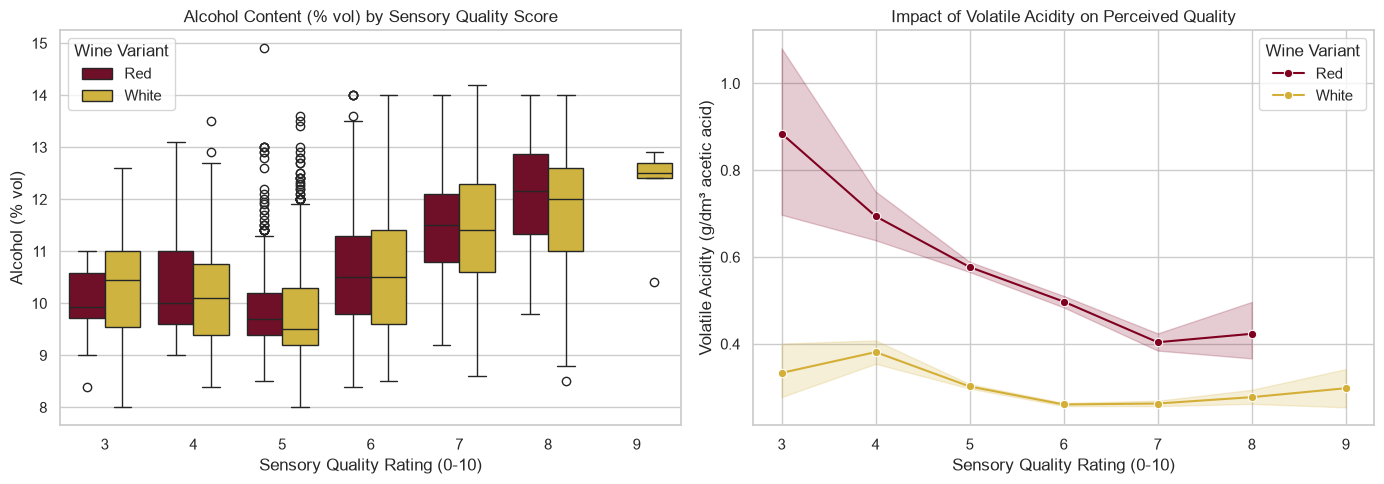

In [20]:
# ---------------------------------------------------------
# 3. DESCRIPTIVE REPORT & VISUALIZATIONS (Rubric Category 3)
# ---------------------------------------------------------
# Extract full joined analytical view for visual reporting
df_viz = pd.read_sql_query("""
    SELECT m.wine_type, c.*, s.quality 
    FROM sample_metadata m
    JOIN chemical_assays c ON m.batch_id = c.batch_id
    JOIN sensory_evaluations s ON m.batch_id = s.batch_id
""", conn)
conn.close()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Alcohol vs Quality Tier across Red & White Wines
sns.boxplot(
    data=df_viz, x='quality', y='alcohol', hue='wine_type',
    palette={'Red': '#800020', 'White': '#e6c229'}, ax=axes[0]
)
axes[0].set_title('Alcohol Content (% vol) by Sensory Quality Score')
axes[0].set_xlabel('Sensory Quality Rating (0-10)')
axes[0].set_ylabel('Alcohol (% vol)')
axes[0].legend(title='Wine Variant')

# Chart 2: Volatile Acidity (Acetic Acid spoilage indicator) vs Quality
sns.lineplot(
    data=df_viz, x='quality', y='volatile_acidity', hue='wine_type',
    marker='o', palette={'Red': '#800020', 'White': '#d4af37'}, ax=axes[1]
)
axes[1].set_title('Impact of Volatile Acidity on Perceived Quality')
axes[1].set_xlabel('Sensory Quality Rating (0-10)')
axes[1].set_ylabel('Volatile Acidity (g/dm³ acetic acid)')
axes[1].legend(title='Wine Variant')

plt.tight_layout()
plt.savefig('wine_physicochemical_report.png', dpi=300)
plt.show()

### Visual Insights & Physicochemical Interpretation

1. **Alcohol Content vs. Sensory Quality (Left):** Across both Red and White variants, median alcohol concentration increases steadily for ratings above 5—rising from ~9.5–9.7% vol at score 5 to ~12.0–12.2% vol at score 8 (with White wines reaching a median of ~12.5% vol at score 9)[cite: 1]. Chemically, higher ethanol enhances perceived body, viscosity, and the volatility of aromatic esters, driving higher sensory scores[cite: 1].
2. **Volatile Acidity vs. Perceived Quality (Right):** Red wines exhibit a pronounced negative relationship between volatile acidity (predominantly acetic acid) and sensory rating, dropping from a mean of ~0.88 g/dm³ at score 3 down to ~0.40 g/dm³ at score 7[cite: 1]. In contrast, White wines maintain consistently low volatile acidity (~0.26–0.38 g/dm³) across all quality tiers, indicating that acetic acid spoilage is a primary differentiator of quality in red wine fermentation[cite: 1].
3. **Sample Distribution & Variance:** The wider 95% confidence bands at the extreme ends (scores 3 and 8–9) reflect class imbalance—the dataset contains far fewer poor or exceptional batches than average batches (scores 5–6), a key consideration for downstream predictive modeling[cite: 1].